In [1]:
import numpy as np
import pandas as pd
import xarray as xr

from netCDF4 import Dataset

import matplotlib.pyplot as plt
#from mpl_toolkits.basemap import Basemap

import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
dsst= xr.open_dataset('../../Data-Other/Article3_data/sst_seasonal_anomalies.nc', engine='netcdf4')
dsst

<xarray.Dataset> Size: 685MB
Dimensions:      (date: 165, latitude: 721, longitude: 1440)
Coordinates:
  * date         (date) <U11 7kB 'Autumn 1983' 'Autumn 1984' ... 'Winter 2024'
  * latitude     (latitude) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude    (longitude) float64 12kB 0.0 0.25 0.5 ... 359.2 359.5 359.8
Data variables:
    sst_anomaly  (date, latitude, longitude) float32 685MB ...

/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/opt/anaconda3/envs/geo_env/lib/python3.11/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


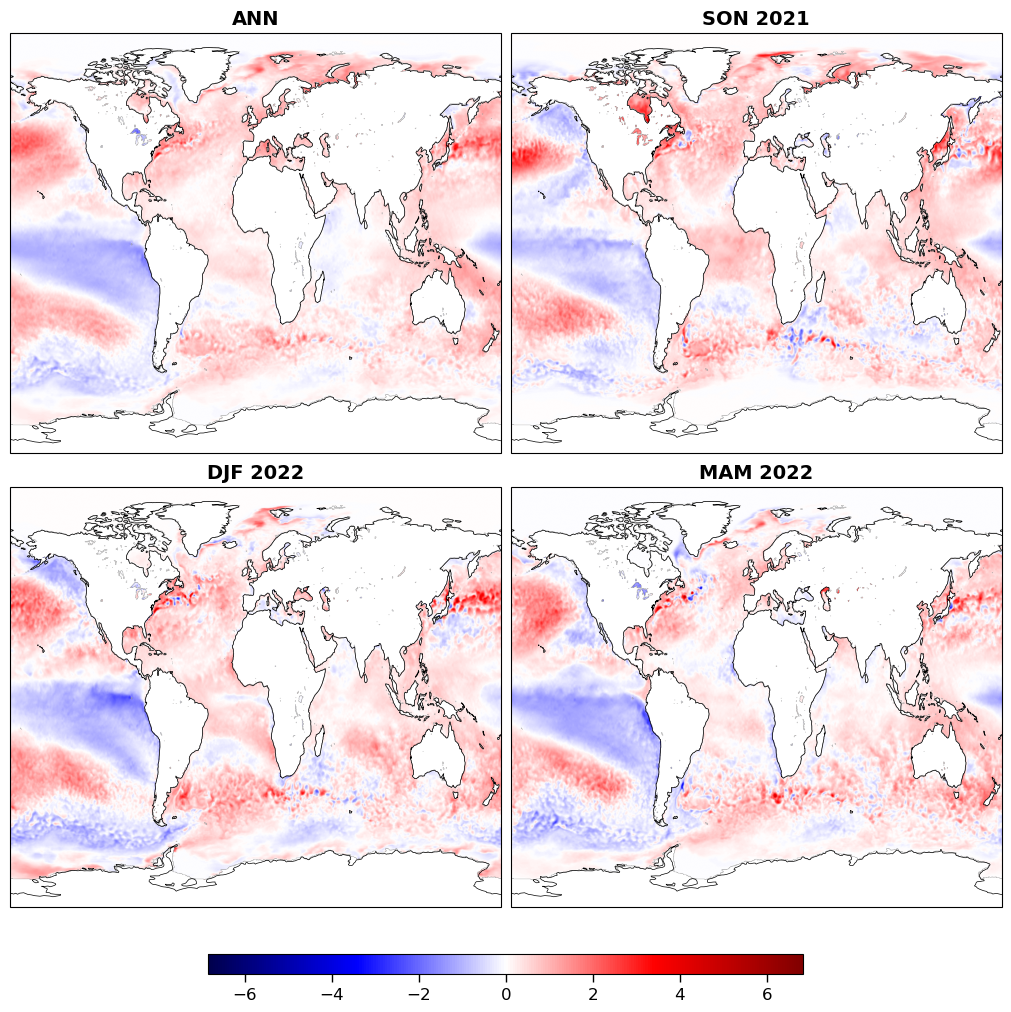

In [2]:
# --- Load Data --- 
anomalies= xr.open_dataset('../../Data-Other/Article3_data/sst_seasonal_anomalies.nc', engine='netcdf4') 
an_anomalies= xr.open_dataset('../../Data-Other/Article3_data/sst_annual_anomalies.nc', engine='netcdf4') 
# --- SELECTION & LABELING --- 
# Define seasonal selections and extract the year
seasons = ['Autumn 2021', 'Winter 2022', 'Spring 2022']
year_label = seasons[1].split()[1]
# Select seasonal and annual data
anomalies = anomalies.sel(date=seasons)
an_anomalies = an_anomalies.sel(year=int(year_label))
# --- COORDINATE FIXES --- 
# Shift longitudes to center on Africa ([-180, 180])
anomalies = anomalies.assign_coords(longitude=(((anomalies.longitude + 180) % 360) - 180)).sortby("longitude")
an_anomalies = an_anomalies.assign_coords(longitude=(((an_anomalies.longitude + 180) % 360) - 180)).sortby("longitude")
# Ensure latitude is sorted ascending
if anomalies.latitude[0] > anomalies.latitude[-1]:
    anomalies = anomalies.sortby("latitude")
if an_anomalies.latitude[0] > an_anomalies.latitude[-1]:
    an_anomalies = an_anomalies.sortby("latitude")
# --- COLOR SCALE CALCULATION ---
vmin = anomalies.to_array().min().item()
vmax = anomalies.to_array().max().item()
absmax = max(abs(vmin), abs(vmax))  # Symmetric scale
# --- LABELS AND DATA LIST ---
# Short labels for seasons
season_map = {'Winter': 'DJF', 'Spring': 'MAM', 'Autumn': 'SON'}
season_labels = [f"{season_map[s.split()[0]]} {s.split()[1]}" for s in seasons]
# Combine annual + seasonal labels
labels = ['ANN'] + season_labels
# Combine annual + seasonal data
anomaly_list = [an_anomalies.to_array().squeeze()] + [anomalies.sel(date=d).to_array().squeeze() for d in anomalies.date.values]
# --- PLOTTING ---
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(10, 10),
    subplot_kw={'projection': ccrs.PlateCarree()},
    constrained_layout=True
)
axes = axes.flatten()
for ax, label, sst_anomaly in zip(axes, labels, anomaly_list):
    # Plot SST anomaly
    im = ax.imshow(
        sst_anomaly[::-1],
        cmap='seismic',
        vmin=-absmax,
        vmax=absmax,
        aspect='auto',
        extent=[
            anomalies.longitude.min(),
            anomalies.longitude.max(),
            anomalies.latitude.min(),
            anomalies.latitude.max()
        ],
        transform=ccrs.PlateCarree()
    )
    # Add map features
    ax.coastlines(resolution='110m', linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='white')
    ax.set_title(label, fontsize=14, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])
# --- COLORBAR ---
cbar = fig.colorbar(im, ax=axes, orientation='horizontal', fraction=0.07, pad=0.05, aspect=30, shrink=0.6)
#cbar.set_label("SST Anomaly (°C)", fontsize=12)
# Style the colorbar ticks and label
cbar.ax.tick_params(labelsize=12, direction='out', length=6, width=1)
cbar.outline.set_linewidth(0.8)
# --- EXPORT / DISPLAY ---
plt.savefig("SSTAnomalies_2022.png", dpi=600)
plt.show()